# MLP_JK_03 — Window comparison (Task 4: a larger input window)

**The question:** does giving the MLP a larger window of neighboring spots lower the prediction error, and does it matter *how* the neighbors are given to it?

Only the **input** changes between rows. Everything else is fixed at the MLP_JK_Best settings: hidden 128, dropout 0.3, weight decay 1e-3, lr 3e-4, early stopping, retrain on all training patients with 3 seeds averaged, and shrinkage toward the training mean with `k` chosen on validation. There is no settings grid.

In every setup the **center spot** goes through StandardScaler + PCA 256, fit on the training spots.

| Setup | Input | Size |
|---|---|---|
| **A** center only | center PCA 256 | 256 |
| **B** 3×3, separate, not compressed | center 256 + 8 neighbors × 256, in fixed slots by direction | 2,304 |
| **C** 3×3, separate, compressed | center 256 + 8 neighbors × 32, in fixed slots by direction | 512 |
| **D** 3×3 average | center 256 + PCA 256 of the 3×3 average | 512 |
| **E** 5×5 average | center 256 + PCA 256 of the 5×5 average | 512 |

**The four Task 4 questions**
1. No window (A) vs. a larger window (B, D, E): does adding neighbors lower the loss?
2. B vs. C: does compressing the neighbors hurt or help?
3. C vs. D (same size, 512): does keeping each neighbor's position help, compared with averaging?
4. D vs. E: does a bigger window (5×5) help?

**Checks (decided before running)**
- Ridge on raw embeddings must reproduce Notebook 5 (pooled PCC 0.187). If not, the notebook stops.
- Setup D is close to MLP_JK_Best (center and 3×3 average, just with the PCA split differently). It runs first, and the notebook stops if its pooled PCC or NRMSE is far from MLP_JK_Best's.
- A difference between setups only counts if it's larger than the spread across the 3 seeds.

**Reads** `~/JHU/BDD/datasets/BDD_HEST`, Notebook 5's scores in `~/JHU/BDD/Experiments/smoothing_control/`, and `~/JHU/BDD/MLP_JK/results/MLP_JK_Best/`.
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_03/` and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths**
- `NOTEBOOK_5_DIR`: Notebook 5's saved scores (ridge check and reference row).
- `BEST_DIR`: MLP_JK_Best's saved scores (reference row and the setup D check).
- `LOG_RESULTS`: whether this notebook adds its rows to `all_results.csv`.

**Evaluation** (copied from Notebook 5): `N_FOLDS`, `N_GENES`, `MIN_TEST_SD`, `SEED`, and the ridge settings `N_INNER_FOLDS`, `ALPHAS`.

**Inputs**
- `SETUPS`: which input setups to run (see the table above).
- `NEIGHBOR_DISTANCE`: how far a neighborhood reaches, in spot spacings. 1.8 = 3×3, 3.0 = 5×5 (as in Notebook 5).
- `SLOT_OFFSETS`: the fixed order of the 8 neighbor slots for B and C, as (dx, dy) steps on the spot grid. Slot 0 is always up-left, slot 1 always up, and so on.
- `N_PCS = 256`: PCA size for the center and for each average. `N_NEIGHBOR_PCS = 32`: how many numbers each neighbor keeps in setup C.

**MLP** (fixed at the MLP_JK_Best settings): `HIDDEN_SIZE`, `DROPOUT`, `WEIGHT_DECAY`, `LEARNING_RATE`, `BATCH_SIZE`, `MAX_EPOCHS`, `PATIENCE`, `SHRINK_FACTORS` (`k` values), `N_VAL_GROUPS` (validation groups of training patients), `N_FINAL_SEEDS`.

**Setup D check**: how far setup D may be from MLP_JK_Best before the notebook stops.

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
NOTEBOOK_5_DIR = os.path.expanduser("~/JHU/BDD/Experiments/smoothing_control")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
BEST_DIR = os.path.join(MLP_DIR, "results", "MLP_JK_Best")
NOTEBOOK_NAME = "MLP_JK_03"
LOG_RESULTS = True
SETUPS = ["A", "B", "C", "D", "E"]
OUT_DIR = os.path.join(MLP_DIR, "results", NOTEBOOK_NAME)
RESULTS_LOG = os.path.join(MLP_DIR, "results", "all_results.csv")

N_FOLDS = 4
N_INNER_FOLDS = 3
N_GENES = 50
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0

NEIGHBOR_DISTANCE = {"3x3": 1.8, "5x5": 3.0}
SLOT_OFFSETS = [(-1, -1), (0, -1), (1, -1), (-1, 0), (1, 0), (-1, 1), (0, 1), (1, 1)]
N_PCS = 256
N_NEIGHBOR_PCS = 32

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

SANITY_PCC_TOLERANCE = 0.02
SANITY_NRMSE_TOLERANCE = 0.015

The names and input sizes of the setups, the device (Apple GPU `mps` if available, otherwise CPU), and fixed seeds. The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.

In [3]:
SETUP_NAMES = {
    "A": "A center only",
    "B": "B 3x3 separate",
    "C": "C 3x3 separate, compressed",
    "D": "D 3x3 average",
    "E": "E 5x5 average",
}
INPUT_SIZES = {
    "A": N_PCS,
    "B": N_PCS + 8 * N_PCS,
    "C": N_PCS + 8 * N_NEIGHBOR_PCS,
    "D": 2 * N_PCS,
    "E": 2 * N_PCS,
}

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Neighborhoods (same definition as Notebook 5) and neighbor slots

**Neighborhoods for the averages (D, E)**, copied from Notebook 5. For each section, the spot spacing = median distance from a spot to its closest other spot. A spot's neighborhood = every spot on the same section within 1.8 spacings (3×3) or 3.0 spacings (5×5), **including the spot itself**. Edge spots are averaged over whatever neighbors exist.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods = {}
for name, distance in NEIGHBOR_DISTANCE.items():
    neighborhoods[name] = find_neighborhoods(distance)
    sizes = np.array([len(n) for n in neighborhoods[name]])
    full = 9 if name == "3x3" else 25
    print(f"{name}: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
          f"min {sizes.min()}, max {sizes.max()} | full ({full}): {np.mean(sizes == full):.1%}")

3x3: spots per neighborhood (incl. itself) mean 8.30, min 1, max 10 | full (9): 70.7%
5x5: spots per neighborhood (incl. itself) mean 21.25, min 2, max 27 | full (25): 18.2%


**Neighbor slots for B and C.** Here each neighbor keeps its position. For every spot, each 3×3 neighbor's offset from the center is divided by the spot spacing and rounded to whole grid steps, (dx, dy). That step decides its slot, in the fixed order of `SLOT_OFFSETS`, so slot 1 always holds the spot directly above (in image coordinates), slot 4 the spot to the right, and so on.

- If two spots round to the same slot (rare, from small irregularities in the grid), the one closer to the exact grid position is kept.
- If a slot is empty (tissue edge or a missing spot), it gets the **center spot's own embedding**.

`neighbor_slots` is a table of row numbers, one row per spot and one column per slot. It says which spot's embedding goes into which slot.

In [6]:
def find_neighbor_slots(max_distance):
    n_spots = len(spots)
    neighbor_slots = np.tile(np.arange(n_spots)[:, None], (1, len(SLOT_OFFSETS)))
    slot_found = np.zeros((n_spots, len(SLOT_OFFSETS)), dtype=bool)
    total_nearby = 0

    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)

        for i, nearby in enumerate(nearby_lists):
            best_error = np.full(len(SLOT_OFFSETS), np.inf)
            for j in nearby:
                if j == i:
                    continue
                total_nearby += 1
                offset = (xy[j] - xy[i]) / spacing
                grid_step = (int(round(offset[0])), int(round(offset[1])))
                if grid_step not in SLOT_OFFSETS:
                    continue
                slot = SLOT_OFFSETS.index(grid_step)
                error = np.sum((offset - np.array(grid_step)) ** 2)
                if error < best_error[slot]:
                    best_error[slot] = error
                    neighbor_slots[rows[i], slot] = rows[j]
                    slot_found[rows[i], slot] = True

    return neighbor_slots, slot_found, total_nearby


neighbor_slots, slot_found, total_nearby = find_neighbor_slots(NEIGHBOR_DISTANCE["3x3"])
missing_per_spot = (~slot_found).sum(axis=1)

print(f"Neighbors within 1.8 spacings: {total_nearby}")
print(f"  placed in a slot: {slot_found.sum()}   not placed (outside the 3x3 steps, or a second spot in a slot): "
      f"{total_nearby - slot_found.sum()}")
print(f"Spots with at least one missing neighbor: {np.sum(missing_per_spot > 0)} of {len(spots)} "
      f"({np.mean(missing_per_spot > 0):.1%})")
print("Missing slots per spot (count of spots):")
print(pd.Series(missing_per_spot).value_counts().sort_index().to_string())
print("Share of spots with each slot filled:")
for slot, step in enumerate(SLOT_OFFSETS):
    print(f"  slot {slot} (dx, dy) = {step}: {slot_found[:, slot].mean():.1%}")

Neighbors within 1.8 spacings: 223488
  placed in a slot: 223480   not placed (outside the 3x3 steps, or a second spot in a slot): 8
Spots with at least one missing neighbor: 8956 of 30600 (29.3%)
Missing slots per spot (count of spots):
0    21644
1     3284
2     1369
3     2533
4     1292
5      371
6       77
7       26
8        4
Share of spots with each slot filled:
  slot 0 (dx, dy) = (-1, -1): 90.0%
  slot 1 (dx, dy) = (0, -1): 92.4%
  slot 2 (dx, dy) = (1, -1): 89.7%
  slot 3 (dx, dy) = (-1, 0): 93.0%
  slot 4 (dx, dy) = (1, 0): 93.0%
  slot 5 (dx, dy) = (-1, 1): 89.7%
  slot 6 (dx, dy) = (0, 1): 92.4%
  slot 7 (dx, dy) = (1, 1): 90.0%


## Step 3. Patient folds (copied from Notebook 5)

`GroupKFold` puts every spot of a patient in the same fold, so the test patients are never seen in training. Each fold is the test set once.

In [7]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 4. Gene choice and scoring (copied from Notebook 5)

**`choose_genes`**: the 50 genes with the highest variance across the **training** spots of a fold.

**`score_model`** gives two kinds of score for every gene:
- **Pooled**: over all test spots of the fold together. **PCC** = correlation between predicted and true expression. **NRMSE** = prediction error divided by the gene's spread (SD) in the test spots.
- **Within patient**: the same, but inside one test patient at a time, then averaged. This asks whether the model ranks spots correctly *within* a tissue, not just whether it gets the patient's overall level right.

The **mean predictor** predicts the training mean for every spot. Its PCC is undefined (the prediction is constant), and its NRMSE is the bar any useful model should get under.

In [8]:
def choose_genes(train_index):
    Y_train = Y[train_index]
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    mean_of_squares = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel()
    variance = mean_of_squares - mean ** 2
    return np.argsort(variance)[::-1][:N_GENES]


def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)

## Step 5. Ridge on raw embeddings (copied from Notebook 5), and the reproduction check

Inside each fold, using **training spots only**: choose the top-50 genes, fit StandardScaler + PCA 256, choose λ per gene with a 3-group patient split of the training patients, fit ridge, predict the test patients. The mean predictor comes from the same fold (the training mean of each gene).

Then the **check**: the pooled PCC and NRMSE must match Notebook 5's `ridge raw` (0.187 / 1.092). If they don't, the `assert` stops the notebook here, because then the setup isn't the same and nothing below would be comparable.

In [9]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred


def run_ridge_fold(X, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]

    gene_index = choose_genes(train_index)
    y_train = Y[train_index][:, gene_index].toarray()
    y_test = Y[test_index][:, gene_index].toarray()

    scaler = StandardScaler(copy=False)
    Z_train = scaler.fit_transform(X[train_index])
    Z_test = scaler.transform(X[test_index])

    pca = PCA(n_components=N_PCS, random_state=SEED, copy=False)
    P_train = pca.fit_transform(Z_train)
    P_test = pca.transform(Z_test)

    alpha_per_gene = choose_alpha_per_gene(P_train, y_train, patient_array[train_index])
    y_pred = fit_and_predict(P_train, y_train, P_test, alpha_per_gene)
    y_mean = np.tile(y_train.mean(axis=0), (len(test_index), 1))

    return {
        "fold": fold,
        "test_index": test_index,
        "genes": all_genes[gene_index],
        "y_test": y_test,
        "y_pred": y_pred,
        "y_mean": y_mean,
        "alpha": alpha_per_gene,
    }


start_time = time.time()
ridge_results = []
for fold in range(N_FOLDS):
    ridge_results.append(run_ridge_fold(X_raw, fold))
    print(f"ridge raw fold {fold} done  ({(time.time() - start_time) / 60:.1f} min)", flush=True)

ridge raw fold 0 done  (0.1 min)


ridge raw fold 1 done  (0.2 min)


ridge raw fold 2 done  (0.3 min)


ridge raw fold 3 done  (0.4 min)


In [10]:
mean_pooled, mean_within = score_model("mean predictor", ridge_results, "y_mean")
ridge_pooled, ridge_within = score_model("ridge raw", ridge_results, "y_pred")

notebook_5_summary = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "summary.csv")).set_index("model")
our_pcc = ridge_pooled["PCC"].mean()
our_nrmse = ridge_pooled["NRMSE"].mean()
notebook_5_pcc = notebook_5_summary.loc["ridge raw", "pooled_PCC"]
notebook_5_nrmse = notebook_5_summary.loc["ridge raw", "pooled_NRMSE"]

print(f"ridge raw, this notebook: pooled PCC {our_pcc:.4f}, NRMSE {our_nrmse:.4f}")
print(f"ridge raw, Notebook 5:    pooled PCC {notebook_5_pcc:.4f}, NRMSE {notebook_5_nrmse:.4f}")

assert abs(our_pcc - notebook_5_pcc) < 0.001 and abs(our_nrmse - notebook_5_nrmse) < 0.001, \
    "Ridge rerun does not reproduce Notebook 5. Stop and find out why before going further."
print("Reproduces Notebook 5.")

ridge raw, this notebook: pooled PCC 0.1868, NRMSE 1.0917
ridge raw, Notebook 5:    pooled PCC 0.1868, NRMSE 1.0917
Reproduces Notebook 5.


## Step 6. PCA inputs for every fold

In each fold, on the **training spots only**, three StandardScaler + PCA 256 transformations are fit:
- `center`: the spots' own embeddings. This is the same transformation ridge uses.
- `mean_3x3`: the 3×3 averaged embeddings (for D).
- `mean_5x5`: the 5×5 averaged embeddings (for E).

Each is then applied to every spot. The neighbors in B and C use the **center PCA**: it is the one shared PCA fit on the training spots' own embeddings, so a neighbor is described in exactly the same way as a center spot. For C, each neighbor keeps only its first 32 components. PCA components are sorted by how much variation they explain, so the first 32 are the same as a PCA with 32 components.

The PCA results are small (30,600 × 256 per input per fold), so all of them are kept. The large 4,608-wide arrays are deleted afterwards to free memory.

In [11]:
def pca_256(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    return pca.transform(scaler.transform(X)).astype(np.float32)


start_time = time.time()
X_mean_3x3 = neighbor_mean(X_raw, neighborhoods["3x3"])
X_mean_5x5 = neighbor_mean(X_raw, neighborhoods["5x5"])
print(f"Averages done ({(time.time() - start_time) / 60:.1f} min)")

fold_inputs = []
for fold in range(N_FOLDS):
    train_index = np.where(fold_of_spot != fold)[0]
    fold_inputs.append({
        "center": pca_256(X_raw, train_index),
        "mean_3x3": pca_256(X_mean_3x3, train_index),
        "mean_5x5": pca_256(X_mean_5x5, train_index),
    })
    print(f"fold {fold}: PCA inputs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

del X_raw, X_mean_3x3, X_mean_5x5

Averages done (0.0 min)


fold 0: PCA inputs done (0.2 min)


fold 1: PCA inputs done (0.4 min)


fold 2: PCA inputs done (0.6 min)


fold 3: PCA inputs done (0.9 min)


**`build_input`** puts together the input of one setup in one fold, by placing blocks side by side. For B and C, `center[neighbor_slots[:, slot]]` looks up the PCA numbers of the spot in that slot for every spot (or the center itself when the slot is empty).

In [12]:
def build_input(setup, fold):
    center = fold_inputs[fold]["center"]
    if setup == "A":
        return center
    if setup == "B":
        parts = [center]
        for slot in range(len(SLOT_OFFSETS)):
            parts.append(center[neighbor_slots[:, slot]])
        return np.concatenate(parts, axis=1)
    if setup == "C":
        parts = [center]
        for slot in range(len(SLOT_OFFSETS)):
            parts.append(center[neighbor_slots[:, slot], :N_NEIGHBOR_PCS])
        return np.concatenate(parts, axis=1)
    if setup == "D":
        return np.concatenate([center, fold_inputs[fold]["mean_3x3"]], axis=1)
    if setup == "E":
        return np.concatenate([center, fold_inputs[fold]["mean_5x5"]], axis=1)
    raise ValueError(f"unknown setup {setup}")


for setup in SETUPS:
    shape = build_input(setup, 0).shape
    assert shape[1] == INPUT_SIZES[setup]
    print(f"{SETUP_NAMES[setup]:28s}: {shape[0]} spots x {shape[1]} numbers")

A center only               : 30600 spots x 256 numbers
B 3x3 separate              : 30600 spots x 2304 numbers
C 3x3 separate, compressed  : 30600 spots x 512 numbers
D 3x3 average               : 30600 spots x 512 numbers
E 5x5 average               : 30600 spots x 512 numbers


## Step 7. The MLP, training, and shrinkage (as in MLP_JK_02, with the settings fixed)

**The network**: input → Linear(input, 128) → ReLU → Dropout 0.3 → Linear(128, 50 genes), with no activation at the end (regression).

**`train_mlp`**: Adam (weight decay 1e-3), MSE loss on genes standardized with the training mean and SD, mini-batches of 256. With validation spots, the weights from the best validation epoch are kept, and training stops after `PATIENCE` epochs without improvement. Without validation spots, it trains for a fixed number of epochs.

**`predict`**: dropout off, predictions converted back to log1p units.

**`shrink`**: `train_mean + k × (prediction − train_mean)`. Shrinking doesn't change PCC; it only changes how spread out the predictions are, so `k` is chosen on NRMSE.

In [13]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 8. One setup in one fold, start to finish

Everything that learns from data uses the fold's **training patients only**:

| Step | Uses |
|---|---|
| Top-50 genes | training spots (chosen once per fold, the same genes for every setup and for ridge) |
| PCA inputs | training spots (Step 6) |
| Choose `k` and the number of epochs | 4 validation groups of training patients. Each group takes a turn as validation while the MLP trains on the other 3. `k` = lowest validation NRMSE averaged over the 4 groups; epochs = median best epoch |
| Final models | **all** training patients, 3 seeds (0, 1, 2), each trained for that many epochs |
| Test patients | used once: the 3 seeds' predictions are averaged and shrunk with `k` toward the training mean |

Each seed's own (shrunk) test predictions are also kept, to measure how much the scores move from seed to seed. As before, the test spots' expression is `NaN` in the array the training reads.

In [14]:
fold_genes = []
for fold in range(N_FOLDS):
    fold_genes.append(choose_genes(np.where(fold_of_spot != fold)[0]))


def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def run_setup_fold(setup, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]
    gene_index = fold_genes[fold]
    genes = all_genes[gene_index]
    no_alpha = np.full(N_GENES, np.nan)

    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    P_device = to_device(build_input(setup, fold))

    val_rows = []
    histories = []
    for group, (fit_rows, val_index) in enumerate(validation_groups(train_index)):
        fit_mean = y_fold[fit_rows].mean(axis=0)
        val_result = {
            "fold": fold,
            "test_index": val_index,
            "genes": genes,
            "y_test": y_fold[val_index],
            "y_mean": np.tile(fit_mean, (len(val_index), 1)),
            "alpha": no_alpha,
        }
        mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")

        trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
        val_pred = predict(trained, P_device, val_index)
        for k in SHRINK_FACTORS:
            val_result["y_pred"] = shrink(val_pred, fit_mean, k)
            scores, _ = score_model("MLP", [val_result], "y_pred")
            val_rows.append({
                "setup": setup, "fold": fold, "val_group": group, "k": k,
                "val_PCC": scores["PCC"].mean(),
                "val_NRMSE": scores["NRMSE"].mean(),
                "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                "best_epoch": trained["best_epoch"],
            })
        history = pd.DataFrame(trained["history"])
        history["setup"] = setup
        history["fold"] = fold
        history["val_group"] = group
        histories.append(history)

    val_table = pd.DataFrame(val_rows)
    by_k = val_table.groupby("k").agg(
        val_PCC=("val_PCC", "mean"),
        val_NRMSE=("val_NRMSE", "mean"),
        val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
        epochs=("best_epoch", "median"),
    ).reset_index()
    chosen = by_k.loc[by_k["val_NRMSE"].idxmin()].to_dict()
    chosen["passes"] = chosen["val_NRMSE"] <= chosen["val_mean_predictor_NRMSE"]
    n_epochs = max(1, int(round(chosen["epochs"])))

    train_mean = y_fold[train_index].mean(axis=0)
    seed_predictions = []
    for seed_number in range(N_FINAL_SEEDS):
        final = train_mlp(P_device, y_fold, train_index, None, n_epochs, SEED + seed_number)
        seed_predictions.append(predict(final, P_device, test_index))
    del P_device

    y_test = Y[test_index][:, gene_index].toarray()
    test_result = {
        "fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
        "y_pred": shrink(np.mean(seed_predictions, axis=0), train_mean, chosen["k"]),
        "alpha": no_alpha,
    }
    seed_results = []
    for prediction in seed_predictions:
        seed_results.append({
            "fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
            "y_pred": shrink(prediction, train_mean, chosen["k"]),
            "alpha": no_alpha,
        })

    chosen.update({"setup": setup, "fold": fold, "final_epochs": n_epochs, "input_size": INPUT_SIZES[setup]})
    return test_result, seed_results, val_table, pd.concat(histories, ignore_index=True), chosen


mlp_results = {}
seed_results = {}
val_tables = []
history_tables = []
chosen_rows = []


def run_setup(setup):
    mlp_results[setup] = []
    seed_results[setup] = [[] for _ in range(N_FINAL_SEEDS)]
    for fold in range(N_FOLDS):
        test_result, fold_seed_results, val_table, history, chosen = run_setup_fold(setup, fold)
        mlp_results[setup].append(test_result)
        for seed_number in range(N_FINAL_SEEDS):
            seed_results[setup][seed_number].append(fold_seed_results[seed_number])
        val_tables.append(val_table)
        history_tables.append(history)
        chosen_rows.append(chosen)
        print(f"{SETUP_NAMES[setup]:28s} fold {fold}: k = {chosen['k']}, {chosen['final_epochs']} epochs  "
              f"({(time.time() - start_time) / 60:.1f} min)", flush=True)
    if device.type == "mps":
        torch.mps.empty_cache()

## Step 9. Test MSE, and the reference rows

**Test MSE** is the loss Task 4 asks for: the average squared difference between predicted and true log1p expression. It's computed per gene over all test spots of a fold, then averaged over genes and folds. It is the square of the error that NRMSE divides by the gene's SD, so `MSE = (NRMSE × test SD)²` for each gene. That formula also gives the MSE of the reference rows from their saved NRMSE, so every row is computed the same way.

**Reference rows**: the mean predictor and ridge raw (run here), the best ridge (`center+mean-3x3`, read from Notebook 5), and **MLP_JK_Best** (read from its saved scores). The check makes sure the saved rows use the same genes in every fold.

In [15]:
test_sd_rows = []
for fold in range(N_FOLDS):
    test_index = np.where(fold_of_spot == fold)[0]
    y_test = Y[test_index][:, fold_genes[fold]].toarray()
    for g, gene in enumerate(all_genes[fold_genes[fold]]):
        test_sd_rows.append({"fold": fold, "gene": gene, "test_SD": np.std(y_test[:, g])})
test_sd = pd.DataFrame(test_sd_rows)


def add_mse(pooled_table):
    table = pooled_table.merge(test_sd, on=["fold", "gene"], how="left")
    table["MSE"] = (table["NRMSE"] * table["test_SD"]) ** 2
    return table


def read_saved_scores(folder, saved_name, new_name):
    pooled = pd.read_csv(os.path.join(folder, "pooled_gene_scores.csv"))
    within = pd.read_csv(os.path.join(folder, "within_patient_gene_scores.csv"))
    pooled = pooled[pooled["model"] == saved_name].copy()
    within = within[within["model"] == saved_name].copy()
    pooled["model"] = new_name
    within["model"] = new_name
    for fold in range(N_FOLDS):
        saved_genes = set(pooled.loc[pooled["fold"] == fold, "gene"])
        assert saved_genes == set(all_genes[fold_genes[fold]]), f"{new_name}, fold {fold}: genes differ"
    return pooled, within


ridge_reference_name = "ridge center+mean-3x3 (Notebook 5)"
best_reference_name = "MLP_JK_Best"
ridge_reference_pooled, ridge_reference_within = read_saved_scores(
    NOTEBOOK_5_DIR, "ridge center+mean-3x3", ridge_reference_name)
best_pooled, best_within = read_saved_scores(BEST_DIR, "MLP center+mean-3x3", best_reference_name)

best_summary = pd.read_csv(os.path.join(BEST_DIR, "summary.csv")).set_index("model").loc["MLP center+mean-3x3"]
best_chosen = pd.read_csv(os.path.join(BEST_DIR, "chosen_settings.csv")).sort_values("fold")
best_val_PCC = best_summary["val_PCC"]
best_val_NRMSE = best_summary["val_NRMSE"]
print("Reference rows match our genes in every fold.")
print(f"MLP_JK_Best: test pooled PCC {best_summary['pooled_PCC']:.4f}, NRMSE {best_summary['pooled_NRMSE']:.4f}, "
      f"validation PCC {best_val_PCC:.4f}")


def score_setup(setup):
    pooled, within = score_model(SETUP_NAMES[setup], mlp_results[setup], "y_pred")
    return add_mse(pooled), within

Reference rows match our genes in every fold.
MLP_JK_Best: test pooled PCC 0.1984, NRMSE 1.0753, validation PCC 0.2113


## Step 10. Run setup D first, and check it against MLP_JK_Best

D gives the MLP the center spot and the 3×3 average, the same information MLP_JK_Best had. The only differences: here they get **two separate PCAs** (256 + 256) instead of one PCA of both together, and the settings are fixed instead of chosen from a grid. So D should land close to MLP_JK_Best, but not exactly on it.

If D's pooled PCC is more than 0.02 away, or its NRMSE more than 0.015 away, the notebook stops here: something in the pipeline would differ from MLP_JK_02, and the other setups wouldn't be comparable.

In [16]:
start_time = time.time()
if "D" in SETUPS:
    run_setup("D")
    d_pooled, _ = score_setup("D")
    d_pcc = d_pooled["PCC"].mean()
    d_nrmse = d_pooled["NRMSE"].mean()
    print(f"\nSetup D:     pooled PCC {d_pcc:.4f}, NRMSE {d_nrmse:.4f}")
    print(f"MLP_JK_Best: pooled PCC {best_summary['pooled_PCC']:.4f}, NRMSE {best_summary['pooled_NRMSE']:.4f}")
    assert abs(d_pcc - best_summary["pooled_PCC"]) <= SANITY_PCC_TOLERANCE, \
        "Setup D's PCC is far from MLP_JK_Best. Stop and check before going further."
    assert abs(d_nrmse - best_summary["pooled_NRMSE"]) <= SANITY_NRMSE_TOLERANCE, \
        "Setup D's NRMSE is far from MLP_JK_Best. Stop and check before going further."
    print("Setup D is close to MLP_JK_Best.")

D 3x3 average                fold 0: k = 0.4, 10 epochs  (0.2 min)


D 3x3 average                fold 1: k = 0.4, 10 epochs  (0.3 min)


D 3x3 average                fold 2: k = 0.4, 9 epochs  (0.5 min)


D 3x3 average                fold 3: k = 0.4, 10 epochs  (0.6 min)



Setup D:     pooled PCC 0.2064, NRMSE 1.0709
MLP_JK_Best: pooled PCC 0.1984, NRMSE 1.0753
Setup D is close to MLP_JK_Best.


## Step 11. Run the other setups

In [17]:
for setup in SETUPS:
    if setup != "D":
        run_setup(setup)

val_scores = pd.concat(val_tables, ignore_index=True)
loss_history = pd.concat(history_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows).sort_values(["setup", "fold"]).reset_index(drop=True)
print("All setups done.")

A center only                fold 0: k = 0.4, 17 epochs  (0.8 min)


A center only                fold 1: k = 0.4, 8 epochs  (0.9 min)


A center only                fold 2: k = 0.4, 14 epochs  (1.1 min)


A center only                fold 3: k = 0.4, 10 epochs  (1.3 min)


B 3x3 separate               fold 0: k = 0.2, 3 epochs  (1.4 min)


B 3x3 separate               fold 1: k = 0.2, 3 epochs  (1.5 min)


... (7 outputs left out)

E 5x5 average                fold 1: k = 0.4, 10 epochs  (3.1 min)


E 5x5 average                fold 2: k = 0.4, 12 epochs  (3.2 min)


E 5x5 average                fold 3: k = 0.4, 12 epochs  (3.4 min)


All setups done.


## Step 12. Results

**Chosen `k` and epochs per fold.** These are chosen on validation patients, separately for each setup and fold. `val_PCC` and `val_NRMSE` are averaged over the 4 validation groups; `passes` means validation NRMSE is no worse than the mean predictor's.

In [18]:
pd.set_option("display.width", 250)
columns = ["setup", "fold", "input_size", "k", "final_epochs", "val_PCC", "val_NRMSE", "val_mean_predictor_NRMSE", "passes"]
print(chosen_settings[columns].round(4).to_string(index=False))

setup  fold  input_size   k  final_epochs  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes
    A     0         256 0.4            17   0.2337     1.1138                    1.1430    True
    A     1         256 0.4             8   0.1494     1.1154                    1.1307    True
    A     2         256 0.4            14   0.1810     1.0703                    1.0955    True
    A     3         256 0.4            10   0.1952     1.0698                    1.0824    True
    B     0        2304 0.2             3   0.2095     1.1216                    1.1430    True
    B     1        2304 0.2             3   0.1342     1.1259                    1.1307    True
    B     2        2304 0.2             7   0.1568     1.0812                    1.0955    True
    B     3        2304 0.2             2   0.1712     1.0701                    1.0824    True
    C     0         512 0.4            20   0.2741     1.1051                    1.1430    True
    C     1         512 0.2            1

**Results table** (test patients, 4 folds). Test MSE and NRMSE: lower is better. Pooled and within-patient PCC: higher is better. The validation columns are what any choice is based on. `chosen_k` lists the `k` of folds 0–3.

In [19]:
pooled_tables = [add_mse(mean_pooled), add_mse(ridge_pooled), add_mse(ridge_reference_pooled), add_mse(best_pooled)]
within_tables = [mean_within, ridge_within, ridge_reference_within, best_within]
for setup in SETUPS:
    p, w = score_setup(setup)
    pooled_tables.append(p)
    within_tables.append(w)
pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)

reference_order = ["mean predictor", "ridge raw", ridge_reference_name, best_reference_name]
setup_order = [SETUP_NAMES[s] for s in SETUPS]
model_order = reference_order + setup_order

summary_rows = []
for model_name in model_order:
    p = pooled[pooled["model"] == model_name]
    w = within[within["model"] == model_name]
    row = {
        "model": model_name,
        "input_size": np.nan,
        "test_MSE": p["MSE"].mean(),
        "pooled_PCC": p["PCC"].mean(),
        "within_PCC": w["PCC_within"].mean(),
        "NRMSE": p["NRMSE"].mean(),
        "val_PCC": np.nan,
        "val_NRMSE": np.nan,
        "chosen_k": "",
    }
    if model_name == "ridge raw":
        row["input_size"] = N_PCS
    if model_name == best_reference_name:
        row["input_size"] = N_PCS
        row["val_PCC"] = best_val_PCC
        row["val_NRMSE"] = best_val_NRMSE
        row["chosen_k"] = "/".join(str(k) for k in best_chosen["k"])
    if model_name in setup_order:
        setup = SETUPS[setup_order.index(model_name)]
        c = chosen_settings[chosen_settings["setup"] == setup]
        row["input_size"] = INPUT_SIZES[setup]
        row["val_PCC"] = c["val_PCC"].mean()
        row["val_NRMSE"] = c["val_NRMSE"].mean()
        row["chosen_k"] = "/".join(str(k) for k in c["k"])
    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)
print(summary.round(4).to_string(index=False))
mean_predictor_nrmse = summary.loc[summary["model"] == "mean predictor", "NRMSE"].iloc[0]

                             model  input_size  test_MSE  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE        chosen_k
                    mean predictor         NaN    1.0092         NaN         NaN 1.0997      NaN        NaN                
                         ridge raw       256.0    0.9837      0.1868      0.1514 1.0917      NaN        NaN                
ridge center+mean-3x3 (Notebook 5)         NaN    0.9890      0.2034      0.1605 1.0930      NaN        NaN                
                       MLP_JK_Best       256.0    0.9661      0.1984      0.1611 1.0753   0.2113     1.0883 0.4/0.4/0.4/0.2
                     A center only       256.0    0.9728      0.1767      0.1433 1.0806   0.1898     1.0923 0.4/0.4/0.4/0.4
                    B 3x3 separate      2304.0    0.9783      0.1888      0.1435 1.0829   0.1679     1.0997 0.2/0.2/0.2/0.2
        C 3x3 separate, compressed       512.0    0.9744      0.2035      0.1625 1.0816   0.2130     1.0876 0.4/0.2/0.4/0.2
        

**Seed spread.** Each of the 3 final models (seeds 0, 1, 2) is scored on its own, with the same `k` and averaged over the 4 folds. The table shows the lowest and highest of the 3. If two setups differ by less than this spread, the difference could just be the luck of the random start. The averaged ensemble (the main result) is often a bit better than any single seed.

In [20]:
spread_rows = []
for setup in SETUPS:
    seed_pcc = []
    seed_mse = []
    seed_nrmse = []
    for seed_number in range(N_FINAL_SEEDS):
        p, _ = score_model("seed", seed_results[setup][seed_number], "y_pred")
        p = add_mse(p)
        seed_pcc.append(p["PCC"].mean())
        seed_mse.append(p["MSE"].mean())
        seed_nrmse.append(p["NRMSE"].mean())
    spread_rows.append({
        "model": SETUP_NAMES[setup],
        "PCC_min": min(seed_pcc), "PCC_max": max(seed_pcc), "PCC_range": max(seed_pcc) - min(seed_pcc),
        "MSE_min": min(seed_mse), "MSE_max": max(seed_mse), "MSE_range": max(seed_mse) - min(seed_mse),
        "NRMSE_min": min(seed_nrmse), "NRMSE_max": max(seed_nrmse),
    })
seed_spread = pd.DataFrame(spread_rows)
print(seed_spread.round(4).to_string(index=False))

                     model  PCC_min  PCC_max  PCC_range  MSE_min  MSE_max  MSE_range  NRMSE_min  NRMSE_max
             A center only   0.1701   0.1757     0.0056   0.9727   0.9762     0.0035     1.0806     1.0827
            B 3x3 separate   0.1698   0.1732     0.0034   0.9796   0.9800     0.0004     1.0836     1.0841
C 3x3 separate, compressed   0.1925   0.2072     0.0147   0.9732   0.9767     0.0035     1.0810     1.0831
             D 3x3 average   0.2003   0.2014     0.0011   0.9593   0.9609     0.0016     1.0716     1.0727
             E 5x5 average   0.1926   0.1963     0.0037   0.9599   0.9613     0.0014     1.0704     1.0720


**Per-fold tables.** Each fold has different test patients. A setup that is better in most folds is more convincing than one that is better only on average.

In [21]:
fold_scores = pooled.groupby(["model", "fold"]).agg(
    MSE=("MSE", "mean"), PCC=("PCC", "mean"), NRMSE=("NRMSE", "mean")).reset_index()
within_fold = within.groupby(["model", "fold"])["PCC_within"].mean().reset_index()
fold_scores = fold_scores.merge(within_fold, on=["model", "fold"])

for column, title in [("MSE", "Test MSE"), ("PCC", "Pooled PCC"), ("NRMSE", "Pooled NRMSE"), ("PCC_within", "Within-patient PCC")]:
    print(f"{title} per fold:")
    print(fold_scores.pivot(index="model", columns="fold", values=column).reindex(model_order).round(4).to_string())
    print()

Test MSE per fold:
fold                                     0       1       2       3
model                                                             
mean predictor                      1.0422  1.1320  0.9242  0.9386
ridge raw                           1.0687  1.0381  0.9487  0.8792
ridge center+mean-3x3 (Notebook 5)  1.1148  1.0121  0.9571  0.8720
MLP_JK_Best                         1.0226  1.0407  0.8893  0.9119
A center only                       1.0299  1.0501  0.9086  0.9026
B 3x3 separate                      1.0219  1.0806  0.8996  0.9110
C 3x3 separate, compressed          1.0277  1.0770  0.8876  0.9053
D 3x3 average                       1.0137  1.0406  0.8891  0.8904
E 5x5 average                       1.0082  1.0451  0.8869  0.8952

Pooled PCC per fold:
fold                                     0       1       2       3
model                                                             
mean predictor                         NaN     NaN     NaN     NaN
ridge raw            

**The four Task 4 comparisons, fold by fold.** Each line is the difference in pooled PCC and in test MSE between two setups, per fold. For MSE, negative means the first setup has the lower (better) loss.

In [22]:
comparisons = [("D", "A"), ("B", "A"), ("E", "A"), ("C", "B"), ("C", "D"), ("E", "D")]
pcc_table = fold_scores.pivot(index="model", columns="fold", values="PCC")
mse_table = fold_scores.pivot(index="model", columns="fold", values="MSE")
for first, second in comparisons:
    if first not in SETUPS or second not in SETUPS:
        continue
    a = SETUP_NAMES[first]
    b = SETUP_NAMES[second]
    pcc_difference = pcc_table.loc[a] - pcc_table.loc[b]
    mse_difference = mse_table.loc[a] - mse_table.loc[b]
    print(f"{first} - {second}:  PCC " + " ".join(f"{d:+.3f}" for d in pcc_difference)
          + f"  (mean {pcc_difference.mean():+.4f}, {first} higher in {(pcc_difference > 0).sum()}/4)"
          + "   |  MSE " + " ".join(f"{d:+.4f}" for d in mse_difference)
          + f"  (mean {mse_difference.mean():+.4f}, {first} lower in {(mse_difference < 0).sum()}/4)")

D - A:  PCC +0.052 +0.015 +0.026 +0.026  (mean +0.0297, D higher in 4/4)   |  MSE -0.0162 -0.0095 -0.0196 -0.0122  (mean -0.0144, D lower in 4/4)
B - A:  PCC +0.022 -0.000 +0.021 +0.006  (mean +0.0121, B higher in 3/4)   |  MSE -0.0080 +0.0304 -0.0090 +0.0083  (mean +0.0055, B lower in 2/4)
E - A:  PCC +0.079 -0.012 +0.025 -0.000  (mean +0.0230, E higher in 2/4)   |  MSE -0.0217 -0.0050 -0.0217 -0.0074  (mean -0.0140, E lower in 4/4)
C - B:  PCC -0.003 +0.021 +0.017 +0.024  (mean +0.0147, C higher in 3/4)   |  MSE +0.0058 -0.0036 -0.0120 -0.0056  (mean -0.0039, C lower in 3/4)
C - D:  PCC -0.033 +0.005 +0.013 +0.003  (mean -0.0030, C higher in 3/4)   |  MSE +0.0140 +0.0364 -0.0015 +0.0149  (mean +0.0160, C lower in 1/4)
E - D:  PCC +0.027 -0.027 -0.001 -0.027  (mean -0.0068, E higher in 1/4)   |  MSE -0.0055 +0.0046 -0.0022 +0.0048  (mean +0.0004, E lower in 2/4)


## Step 13. Plots

**Test MSE and pooled PCC per setup.** Bars are the average over folds; dots are the 4 folds. For the setups, the black line shows the range across the 3 seeds (lowest to highest). The dashed line is the mean predictor's MSE.

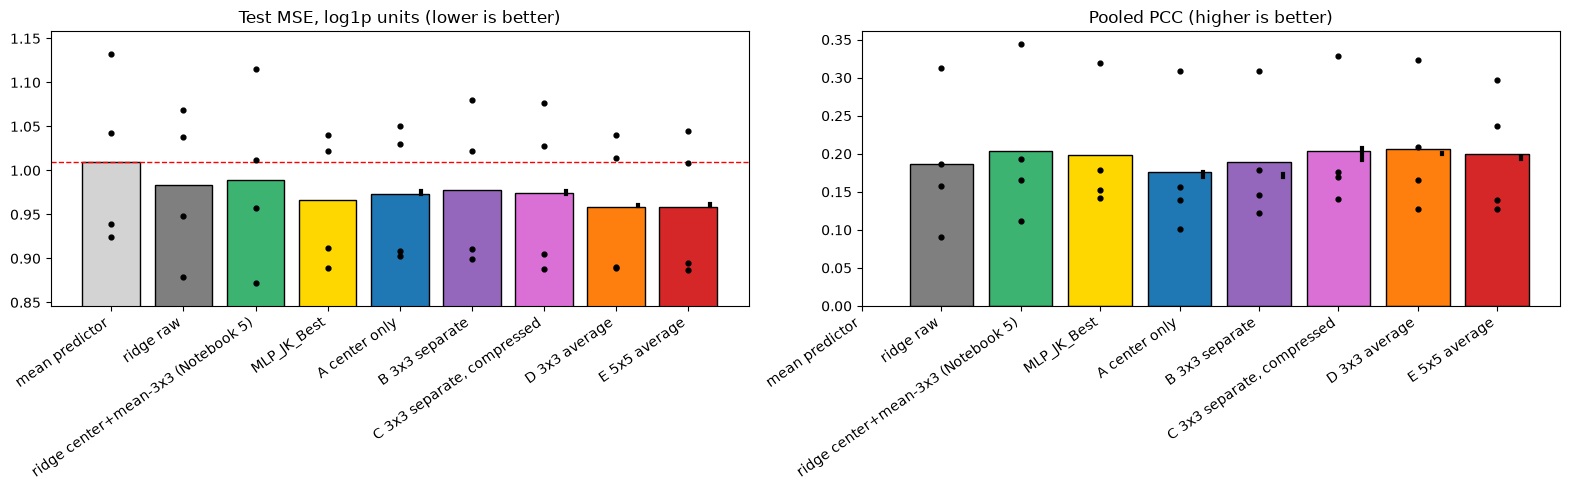

In [23]:
colors = {
    "mean predictor": "lightgrey",
    "ridge raw": "tab:gray",
    ridge_reference_name: "mediumseagreen",
    best_reference_name: "gold",
    SETUP_NAMES["A"]: "tab:blue",
    SETUP_NAMES["B"]: "tab:purple",
    SETUP_NAMES["C"]: "orchid",
    SETUP_NAMES["D"]: "tab:orange",
    SETUP_NAMES["E"]: "tab:red",
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(model_order))
for ax, column, spread_column, title in [(axes[0], "MSE", "MSE", "Test MSE, log1p units (lower is better)"),
                                         (axes[1], "PCC", "PCC", "Pooled PCC (higher is better)")]:
    for i, model_name in enumerate(model_order):
        values = fold_scores.loc[fold_scores["model"] == model_name, column]
        if values.notna().any():
            ax.bar(i, values.mean(), color=colors[model_name], edgecolor="black")
            ax.scatter(np.full(len(values), i), values, color="black", s=12, zorder=3)
        spread = seed_spread[seed_spread["model"] == model_name]
        if len(spread) > 0:
            ax.plot([i + 0.3, i + 0.3], [spread[f"{spread_column}_min"].iloc[0], spread[f"{spread_column}_max"].iloc[0]],
                    color="black", linewidth=3)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=35, ha="right")
    ax.set_title(title)
mean_mse = summary.loc[summary["model"] == "mean predictor", "test_MSE"].iloc[0]
axes[0].axhline(mean_mse, color="red", linestyle="--", linewidth=1)
low = fold_scores["MSE"].min()
high = fold_scores["MSE"].max()
axes[0].set_ylim(low - 0.1 * (high - low), high + 0.1 * (high - low))
plt.tight_layout()
save_figure("1_mse_and_pcc.png")
plt.show()

**Per fold.** Each line is one test fold. Lines going up or down together between two setups mean the difference is consistent across patients.

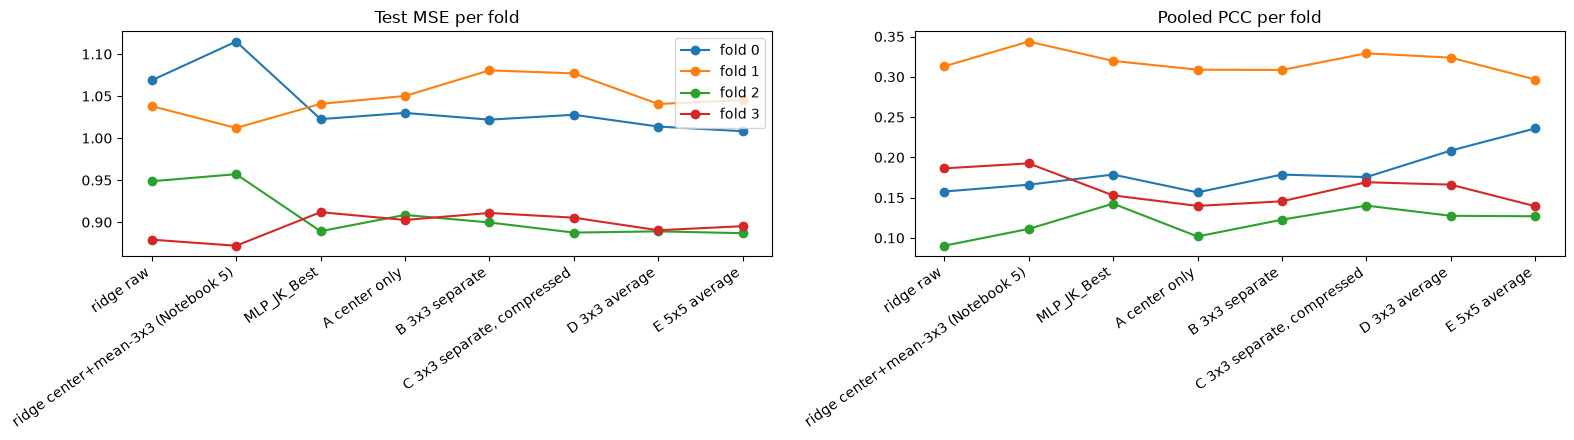

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
models_to_plot = [m for m in model_order if m != "mean predictor"]
for ax, column, title in [(axes[0], "MSE", "Test MSE per fold"), (axes[1], "PCC", "Pooled PCC per fold")]:
    table = fold_scores.pivot(index="model", columns="fold", values=column)
    for fold in range(N_FOLDS):
        ax.plot(range(len(models_to_plot)), [table.loc[m, fold] for m in models_to_plot], marker="o", label=f"fold {fold}")
    ax.set_xticks(range(len(models_to_plot)))
    ax.set_xticklabels(models_to_plot, rotation=35, ha="right")
    ax.set_title(title)
axes[0].legend()
plt.tight_layout()
save_figure("2_per_fold.png")
plt.show()

## Step 14. Does any setup beat MLP_JK_Best?

The rule: a setup replaces MLP_JK_Best only if its **validation PCC is higher** than MLP_JK_Best's and its validation NRMSE is no worse than the mean predictor's. Test scores are not used.

Note: MLP_JK_Best's validation PCC came from picking the best of 8 settings in each fold, so it is a little optimistic. The setups here use one fixed setting, so they are at a small disadvantage in this comparison.

In [25]:
best_rows = []
for setup in SETUPS:
    c = chosen_settings[chosen_settings["setup"] == setup]
    val_PCC = c["val_PCC"].mean()
    passes = c["val_NRMSE"].mean() <= c["val_mean_predictor_NRMSE"].mean()
    best_rows.append({
        "setup": setup,
        "val_PCC": val_PCC,
        "val_NRMSE": c["val_NRMSE"].mean(),
        "val_mean_predictor_NRMSE": c["val_mean_predictor_NRMSE"].mean(),
        "passes_NRMSE_rule": passes,
        "beats_best": passes and val_PCC > best_val_PCC,
    })
best_check = pd.DataFrame(best_rows)
print(f"MLP_JK_Best validation PCC: {best_val_PCC:.4f}\n")
print(best_check.round(4).to_string(index=False))

winners = best_check[best_check["beats_best"]]
if len(winners) == 0:
    new_best_setup = None
    print("\nNo setup beats MLP_JK_Best. It stays as it is.")
else:
    new_best_setup = winners.sort_values("val_PCC", ascending=False).iloc[0]["setup"]
    print(f"\nSetup {new_best_setup} beats MLP_JK_Best on validation and should replace it.")

MLP_JK_Best validation PCC: 0.2113

setup  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes_NRMSE_rule  beats_best
    A   0.1898     1.0923                    1.1129               True       False
    B   0.1679     1.0997                    1.1129               True       False
    C   0.2130     1.0876                    1.1129               True        True
    D   0.2076     1.0888                    1.1129               True       False
    E   0.2256     1.0840                    1.1129               True        True

Setup E beats MLP_JK_Best on validation and should replace it.


## Step 15. Save results and add them to the log

`all_results.csv` gets one row per model run in this notebook: the mean predictor, ridge raw, and the 5 setups. (The reference rows read from other notebooks aren't added again.) If this notebook is run again, its old rows are replaced instead of duplicated.

In [26]:
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
seed_spread.to_csv(os.path.join(OUT_DIR, "seed_spread.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
pooled.to_csv(os.path.join(OUT_DIR, "pooled_gene_scores.csv"), index=False)
within.to_csv(os.path.join(OUT_DIR, "within_patient_gene_scores.csv"), index=False)
val_scores.to_csv(os.path.join(OUT_DIR, "validation_scores.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)
best_check.to_csv(os.path.join(OUT_DIR, "best_check.csv"), index=False)
loss_history.to_csv(os.path.join(OUT_DIR, "loss_history.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "setups": SETUPS,
    "setup_names": SETUP_NAMES,
    "input_sizes": INPUT_SIZES,
    "new_best_setup": new_best_setup,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "slot_offsets": SLOT_OFFSETS,
    "n_pcs": N_PCS,
    "n_neighbor_pcs": N_NEIGHBOR_PCS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "n_genes": N_GENES,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        if row["model"] in [ridge_reference_name, best_reference_name]:
            continue
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": row["model"],
            "pooled_PCC": row["pooled_PCC"],
            "within_patient_PCC": row["within_PCC"],
            "NRMSE": row["NRMSE"],
            "mean_predictor_NRMSE": mean_predictor_nrmse,
            "val_PCC": row["val_PCC"],
            "val_NRMSE": row["val_NRMSE"],
            "date": today,
        })
    new_rows = pd.DataFrame(log_rows)
    if os.path.exists(RESULTS_LOG):
        old_rows = pd.read_csv(RESULTS_LOG)
        old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
        new_rows = pd.concat([old_rows, new_rows], ignore_index=True)
    new_rows.to_csv(RESULTS_LOG, index=False)
    print(new_rows.round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

 notebook                  condition  pooled_PCC  within_patient_PCC  NRMSE  mean_predictor_NRMSE  val_PCC  val_NRMSE       date
MLP_JK_01             mean predictor         NaN                 NaN 1.0997                1.0997      NaN        NaN 2026-11-06
MLP_JK_01                  ridge raw      0.1868              0.1514 1.0917                1.0997      NaN        NaN 2026-11-06
MLP_JK_01                    MLP raw      0.1721              0.1434 1.1382                1.0997   0.1525     1.1353 2026-11-06
MLP_JK_01        MLP center+mean-3x3      0.2160              0.1563 1.1141                1.0997   0.1495     1.1303 2026-11-06
MLP_JK_02             mean predictor         NaN                 NaN 1.0997                1.0997      NaN        NaN 2026-11-06
MLP_JK_02                  ridge raw      0.1868              0.1514 1.0917                1.0997      NaN        NaN 2026-11-06
MLP_JK_02                    MLP raw      0.1767              0.1433 1.0806                1.0997

## Summary in plain words: Task 4 (a larger input window)

**Checks first**
- Ridge on raw embeddings reproduced Notebook 5 (pooled PCC 0.1868, NRMSE 1.0917).
- Setup D came out close to MLP_JK_Best, as expected (pooled PCC 0.206 vs. 0.198, NRMSE 1.071 vs. 1.075), so the pipeline matches MLP_JK_02.
- **Neighbor slots.** Every one of the 223,480 neighbors placed in a slot went to the direction that the spot barcodes also give (the barcodes encode each spot's grid position, e.g. `024x011`), so the slots are right.
- **The 8 neighbors without a slot** are 4 pairs of spots, in sections SPA51, SPA58, SPA82 and SPA108. Each pair is **two grid steps apart** (e.g. `024x011` and `024x013`), but sits a little closer than usual (1.75–1.79 spacings), so they fall inside the 1.8-spacing radius. Their offset rounds to 2 steps, which isn't one of the 8 directions of the 3×3 square, so they were correctly left out of the slots. The 3×3 *average* (D, and MLP_JK_Best) does include them, which is why a few neighborhoods have 10 spots instead of 9. With 8 of 30,600 spots affected, it makes no difference to the results.

### What each score means

| Score | What it means | Good vs. bad |
|---|---|---|
| **Test MSE** (the Task 4 loss) | Average squared difference between predicted and true expression (log1p), over all test spots and the 50 genes | Lower is better. The mean predictor (1.009) is the bar. Gains are small in absolute terms, because most spot-to-spot variation isn't predictable from these image embeddings |
| **Pooled PCC** | Correlation between predicted and true expression over all test spots | 0 = no relation, 1 = perfect. ~0.2 is the current level |
| **Within-patient PCC** | The same correlation inside one patient at a time: does the model rank spots within a tissue? | Higher is better |
| **NRMSE** | The error divided by the gene's spread. Below the mean predictor (1.100) = better than guessing the average | Lower is better |
| **Validation PCC / NRMSE** | The same scores on held-out *training* patients. The only scores used to choose | Higher PCC, lower NRMSE |
| **Seed spread** | How much a score moves between the 3 random starts | A difference between setups smaller than this could be luck |

### What we got

| Setup | Input size | Test MSE | Pooled PCC | Within-patient PCC | NRMSE | Validation PCC | k |
|---|---|---|---|---|---|---|---|
| mean predictor | — | 1.009 | — | — | 1.100 | — | — |
| ridge raw | 256 | 0.984 | 0.187 | 0.151 | 1.092 | — | — |
| ridge center+mean-3x3 (NB 5) | 256 | 0.989 | 0.203 | 0.161 | 1.093 | — | — |
| MLP_JK_Best (from 02) | 256 | 0.966 | 0.198 | 0.161 | 1.075 | 0.211 | 0.4/0.4/0.4/0.2 |
| **A** center only | 256 | 0.973 | 0.177 | 0.143 | 1.081 | 0.190 | 0.4 ×4 |
| **B** 3×3 separate | 2,304 | 0.978 | 0.189 | 0.144 | 1.083 | 0.168 | 0.2 ×4 |
| **C** 3×3 separate, compressed | 512 | 0.974 | 0.204 | 0.163 | 1.082 | 0.213 | 0.4/0.2/0.4/0.2 |
| **D** 3×3 average | 512 | **0.958** | **0.206** | 0.158 | 1.071 | 0.208 | 0.4 ×4 |
| **E** 5×5 average | 512 | 0.959 | 0.200 | **0.169** | **1.070** | **0.226** | 0.4 ×4 |

Seed spread (lowest to highest of the 3 seeds): test MSE 0.0004–0.0035, pooled PCC 0.001–0.015 (C has the widest spread, 0.015).

### The four questions

**1. No window (A) vs. a larger window (B, D, E): does adding neighbors lower the loss?**
**Yes, when the neighbors are averaged.**
- **D vs. A:** test MSE 0.0144 lower (lower in all 4 folds), and pooled PCC 0.030 higher (higher in all 4 folds). Both differences are several times the seed spread, so this is a real effect.
- **E vs. A:** test MSE 0.0140 lower (all 4 folds), and pooled PCC 0.023 higher. The PCC gain is mixed: higher in only 2 of 4 folds.
- **B vs. A:** adding the 8 neighbors as raw separate blocks did **not** lower the loss. Test MSE was 0.0055 *higher* (lower in only 2 of 4 folds), with pooled PCC +0.012 and within-patient PCC unchanged. B is the setup that overfits most: early stopping chose only 2–7 epochs, every fold chose the strongest shrinkage (k = 0.2), and its validation PCC was the lowest of all (0.168).
- **Filled slots.** In B (and C), **29% of spots have at least one empty slot filled with their own center embedding**. For those spots the "neighbors" partly repeat the center, and the model can't tell a filled slot from a real neighbor. The averages in D and E handle the edge differently: they average over whichever neighbors exist. So part of B's (and C's) weaker showing against A could come from these filled slots, not only from the input size.

**2. B vs. C: does compressing the neighbors hurt or help?**
**It helps, or at least doesn't hurt.**
- Going from 256 to 32 numbers per neighbor gave pooled PCC +0.015 (higher in 3 of 4 folds), within-patient PCC +0.019, and test MSE 0.004 lower (3 of 4 folds).
- On test, these differences are about the size of the seed spread (C's seed range is 0.015 for PCC and 0.0035 for MSE), so on their own they're weak evidence.
- Validation favors C clearly (0.213 vs. 0.168). Fewer inputs means less to overfit: C trained for 18–22 epochs before stopping, compared with B's 2–7.

**3. C vs. D (same size, 512): does keeping neighbor positions help?**
**No.**
- Pooled PCC is the same (C 0.204, D 0.206). The difference is smaller than the seed spread.
- Within-patient PCC is nearly the same (0.163 vs. 0.158).
- The plain 3×3 average gives a clearly lower loss: test MSE 0.958 vs. 0.974 (0.016 better, lower in 3 of 4 folds, well beyond the seed spread).
- Knowing which direction each neighbor is in doesn't add information the model can use. Averaging works better, probably because it smooths out noise in the individual embeddings (the same finding as Notebook 5).

**4. D vs. E: does a bigger window (5×5) help?**
**Not for the loss.**
- **Loss:** test MSE is the same (0.9584 vs. 0.9589). The difference is 0.0004, smaller than the seed spread.
- **PCC is mixed.** Pooled PCC is slightly lower with 5×5 (−0.007, higher in only 1 of 4 folds), while within-patient PCC is higher (0.169 vs. 0.158, the best of any model so far).
- **Validation** favors 5×5 (0.226 vs. 0.208).
- A larger window seems to help ranking spots *within* a tissue a little, but the evidence is weak.

**Bottom line for Task 4:** a larger window lowers the loss when the neighbors are **averaged** (D, E: about 1.5% lower MSE than the center spot alone, consistent across all folds). Giving the neighbors separately doesn't help: uncompressed (B) it overfits, and compressed (C) it only matches the average. Going from 3×3 to 5×5 makes no difference to the loss.

### Best model
By the rule (highest validation PCC, with validation NRMSE no worse than the mean predictor's), **setup E beats MLP_JK_Best**: validation PCC 0.226 vs. 0.211, validation NRMSE 1.084 vs. mean predictor 1.113. C also passes (0.213), but E is higher. On test, E has a lower MSE than the old best (0.959 vs. 0.966) and the highest within-patient PCC so far (0.169), with about the same pooled PCC (0.200 vs. 0.198). MLP_JK_Best is updated to setup E.